In [8]:
import numpy as np
import pandas as pd
import os
import s3fs
import sys
import cartiflette #Attention, cartiflette n'est pas disponible par défaut sur Onyxia
sys.path.append('../outils')

import fonctions_nomenclature as fnom
import fonctions_preparation_table as fprep
%load_ext autoreload
%autoreload 2

np.random.seed(123)

# Create filesystem object
S3_ENDPOINT_URL = "https://" + os.environ["AWS_S3_ENDPOINT"]
fs = s3fs.S3FileSystem(client_kwargs={'endpoint_url': S3_ENDPOINT_URL})
BUCKET = "mathildedonnenfeld/diffusion/bistrots_et_bulletins"


FILE_KEY_S3 = "table_analyse_muni.csv"
FILE_PATH_S3 = BUCKET + "/" + FILE_KEY_S3

with fs.open(FILE_PATH_S3, mode="rb") as file_in:
    df = pd.read_csv(file_in, sep=",")

df.head()   

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


/tmp/ipykernel_77632/4032096808.py:26: DtypeWarning: Columns (2: CODGEO, 7: dep, 8: code_commune, 11: Code commune) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_in, sep=",")


,Unnamed: 0.1,Unnamed: 0,CODGEO,LIBGEO,POPULATION,NIVVIE_MEDIAN,TAUX_PAUVRETE,dep,code_commune,nb_etablissements,...,Libellé commune,Nombre candidats,ind1,ind2,ind3,ind4,part_votes_liste_gagnante,Abstentions,Exprimés,tour
0,0,0,01001,L'Abergement-Clémenciat,860,28270.0,NaN,01,01001,1.0,...,L'Abergement-Clémenciat,1.0,2.0,2.0,2.0,2.0,1.0000,305.0,345.0,1.0
1,1,1,01002,L'Abergement-de-Varey,270,28140.0,NaN,01,NaN,NaN,...,L'Abergement-de-Varey,2.0,2.0,2.0,2.0,2.0,0.5588,40.0,204.0,1.0
2,2,2,01004,Ambérieu-en-Bugey,15934,24210.0,18.0,01,01004,10.0,...,Ambérieu-en-Bugey,3.0,0.0,0.0,0.0,0.0,0.5415,4520.0,4081.0,1.0
3,3,3,01005,Ambérieux-en-Dombes,1906,28120.0,5.0,01,01005,1.0,...,Ambérieux-en-Dombes,1.0,2.0,2.0,2.0,2.0,1.0000,770.0,526.0,1.0
4,4,4,01006,Ambléon,115,NaN,NaN,01,NaN,NaN,...,Ambléon,2.0,2.0,2.0,2.0,2.0,0.7778,14.0,90.0,1.0


In [9]:
df.columns

Index(['Unnamed: 0.1', 'Unnamed: 0', 'CODGEO', 'LIBGEO', 'POPULATION',
       'NIVVIE_MEDIAN', 'TAUX_PAUVRETE', 'dep', 'code_commune',
       'nb_etablissements', 'age_moyen_bistrots', 'Code commune',
       'Libellé commune', 'Nombre candidats', 'ind1', 'ind2', 'ind3', 'ind4',
       'part_votes_liste_gagnante', 'Abstentions', 'Exprimés', 'tour'],
      dtype='str')

In [10]:
# Modélisation simple, paramètres fixés

# Il va dans un seul bistrot par ville
nb_bistrots_par_ville = 1

# Dans 1000 bistrots au total
nb_bistrots_total = 1000

# On sélectionne donc les 1000 premières villes
nombre_villes = nb_bistrots_total/nb_bistrots_par_ville

# Paramètre de la stratégie de classement selon le nombre de bistrots 
croissant = True

# On crée la sous-table qui contient ces villes 
bistrots_visites = df.sort_values("nb_etablissements", ascending=croissant).head(int(nombre_villes)) #Arrondi à l'inférieur

# On calcule la proportion du nombre de bistrots visités dans la ville par rapport au nombre de bistrots totaux de la ville
bistrots_visites['part_des_etablissements_visites'] = nb_bistrots_par_ville/bistrots_visites['nb_etablissements']

# On applique cette proportion aux abstentionnistes de la ville
bistrots_visites['voix_pour_attal'] = bistrots_visites['part_des_etablissements_visites']*bistrots_visites['Abstentions']

# On calcule le nombre de voix obtenues par la liste gagnante
bistrots_visites['voix_LG'] = bistrots_visites['part_votes_liste_gagnante']*bistrots_visites['Exprimés']

# Indicatrice de victoire 
bistrots_visites['victoire_attal'] =  bistrots_visites['voix_pour_attal'] > bistrots_visites['voix_LG']

codes_communes_gagnees = bistrots_visites[bistrots_visites['victoire_attal']==True].CODGEO

decompte_communes = (bistrots_visites['victoire_attal'] == True).sum()
part_communes = decompte_communes / bistrots_visites.shape[0]

print(f"Gabriel Attal a emporté {decompte_communes} communes grâce à ses visites, "
      f"soit {part_communes:.1%} des communes visitées ! Bravo !")


Gabriel Attal a emporté 308 communes grâce à ses visites, soit 30.8% des communes visitées ! Bravo !


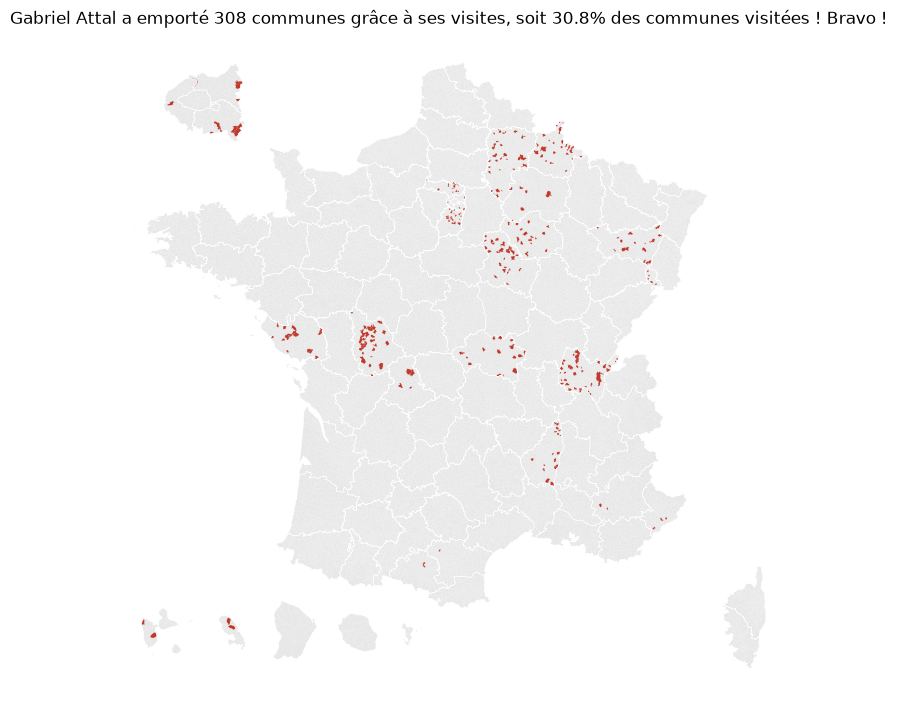

In [13]:
# Partie carto codée avec Claude Code
import matplotlib.pyplot as plt
from cartiflette import carti_download   # versions anciennes : from cartiflette.client import carti_download

# Fond de carte : communes de France, DROM rapprochés
communes = carti_download(
    values=["France"],
    crs=4326,
    borders="COMMUNE_ARRONDISSEMENT",
    vectorfile_format="parquet",   
    simplification=50,
    filter_by="FRANCE_ENTIERE_DROM_RAPPROCHES",
    source="EXPRESS-COG-CARTO-TERRITOIRE",
    year=2025,
)

# Départements, pour avoir des repères sur la carte
departements = carti_download(
    values=["France"],
    crs=4326,
    borders="DEPARTEMENT",
    vectorfile_format="parquet",
    simplification=50,
    filter_by="FRANCE_ENTIERE_DROM_RAPPROCHES",
    source="EXPRESS-COG-CARTO-TERRITOIRE",
    year=2025,
)

# Ta liste de codes communes (en texte !)
codes = [str(c).zfill(5) for c in codes_communes_gagnees]
communes["selection"] = communes["INSEE_COG"].isin(codes)

fig, ax = plt.subplots(figsize=(9, 9))
communes.plot(ax=ax, color="#e8e8e8", linewidth=0)
communes[communes["selection"]].plot(ax=ax, color="#c0392b", linewidth=0)
departements.boundary.plot(ax=ax, color="white", linewidth=0.4)
ax.set_axis_off()
ax.set_title(f"Gabriel Attal a emporté {decompte_communes} communes grâce à ses visites, "
      f"soit {part_communes:.1%} des communes visitées ! Bravo !")
plt.show()

In [ ]:
# Modélisation plus complexe (à transformer en version interactive ?)

#Paramètres à fixer :

# Nb de bistrots par ville

#Nb de bistrots complet

# Stratégie aggressive ou passive (taux appliqué aux abstentionnistes ou volé à la LG)

# Sélection des bistrots (par ordre croissant ou décroissant de nb de bistrots, de revenu médian, de taux de pauvreté, de % de la LG, Abstentions, Population, filtrage des tours...)


In [23]:
import itertools
import pandas as pd

def calcul_codes(croissant=True):          # On POC avec un seul paramètre

    nb_bistrots_par_ville = 1
    nb_bistrots_total = 1000
    nombre_villes = nb_bistrots_total/nb_bistrots_par_ville

    # On crée la sous-table qui contient ces villes 
    bistrots_visites = df.sort_values("nb_etablissements", ascending=croissant).head(int(nombre_villes)) #Arrondi à l'inférieur

    # On calcule la proportion du nombre de bistrots visités dans la ville par rapport au nombre de bistrots totaux de la ville
    bistrots_visites['part_des_etablissements_visites'] = nb_bistrots_par_ville/bistrots_visites['nb_etablissements']

    # On applique cette proportion aux abstentionnistes de la ville
    bistrots_visites['voix_pour_attal'] = bistrots_visites['part_des_etablissements_visites']*bistrots_visites['Abstentions']

    # On calcule le nombre de voix obtenues par la liste gagnante
    bistrots_visites['voix_LG'] = bistrots_visites['part_votes_liste_gagnante']*bistrots_visites['Exprimés']

    # Indicatrice de victoire 
    bistrots_visites['victoire_attal'] =  bistrots_visites['voix_pour_attal'] > bistrots_visites['voix_LG']

    codes_communes_gagnees = bistrots_visites[bistrots_visites['victoire_attal']==True].CODGEO

    decompte_communes = (bistrots_visites['victoire_attal'] == True).sum()
    part_communes = decompte_communes / bistrots_visites.shape[0]   

    return    codes_communes_gagnees     

grille = {"croissant": [True, False]}   # les valeurs proposées sur la page

resultats = []
for valeurs in itertools.product(*grille.values()):
    params = dict(zip(grille, valeurs))
    codes = calcul_codes(**params)
    resultats.append(pd.DataFrame({"code": codes, **params}))

res = pd.concat(resultats, ignore_index=True)

# Ajout des coordonnées des centroïdes pour la carte
centres = communes.to_crs(2154).centroid.to_crs(4326)
coords = pd.DataFrame({"code": communes["INSEE_COG"], "nom": communes["NOM"],
                    "x": centres.x, "y": centres.y})
res = res.merge(coords, on="code", how="left")

In [19]:
res

,code,croissant,nom,x,y
0,01047,True,Blyes,5.251671,45.847065
1,01049,True,La Boisse,5.028324,45.844641
2,01064,True,Briord,5.485493,45.770639
3,01079,True,Champagne-en-Valromey,5.693147,45.931960
4,01081,True,Champfromier,5.822268,46.220470
...,...,...,...,...,...
303,85089,True,La Ferrière,-1.334385,46.721796
304,85095,True,Froidfond,-1.755548,46.879320
305,85098,True,La Genétouze,-1.503593,46.725330
306,85100,True,Givrand,-1.878035,46.682413
